# Assignment 4 - Greeks and Finite Difference

In [1]:
import sys
from pathlib import Path

current = Path(Path().resolve())
sys.path.insert(0, str(current))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from enums import *
from contract import *
from model import *
from market_data import *
from pricer import *

%matplotlib inline

MarketData.initialize()

QuantCourseBP 1a2e3b80fdd6984a1c4ba8788a1e01645f8ef688*


### 1. Test combinations

In [2]:
contract = EuropeanContract(Stock.TEST_COMPANY, PutCallFwd.CALL, LongShort.LONG, 100.0, 1.0)
model = FlatVolModel(Stock.TEST_COMPANY)
pricer = EuropeanAnalyticPricer(contract, model, Params())

ana_d = pricer.calc_delta(GreekMethod.ANALYTIC)
ana_g = pricer.calc_gamma(GreekMethod.ANALYTIC)

res = []
for b_type in [BumpType.RELATIVE, BumpType.ABSOLUTE]:
    for fd_m in [FiniteDifferenceMethod.FORWARD, FiniteDifferenceMethod.BACKWARD, FiniteDifferenceMethod.CENTRAL]:
        Pricer.fd_method = fd_m
        Pricer.bump_type = b_type
        Pricer.bump_size = 0.01 if b_type == BumpType.RELATIVE else 1.0
        res.append({
            'method': fd_m.value,
            'type': b_type.value,
            'delta_num': pricer.calc_delta(GreekMethod.BUMP),
            'delta_err': abs(pricer.calc_delta(GreekMethod.BUMP) - ana_d),
            'gamma_num': pricer.calc_gamma(GreekMethod.BUMP),
            'gamma_err': abs(pricer.calc_gamma(GreekMethod.BUMP) - ana_g)
        })

pd.DataFrame(res)

,method,type,delta_num,delta_err,gamma_num,gamma_err
0,FORWARD,RELATIVE,0.630532,0.006280,0.012384,2.633075e-04
1,BACKWARD,RELATIVE,0.617885,0.006367,0.012904,2.561732e-04
2,CENTRAL,RELATIVE,0.624208,0.000043,0.012647,5.092095e-07
3,FORWARD,ABSOLUTE,0.630532,0.006280,0.012384,2.633075e-04
4,BACKWARD,ABSOLUTE,0.617885,0.006367,0.012904,2.561732e-04
5,CENTRAL,ABSOLUTE,0.624208,0.000043,0.012647,5.092095e-07


### 2. Numerical error comparison

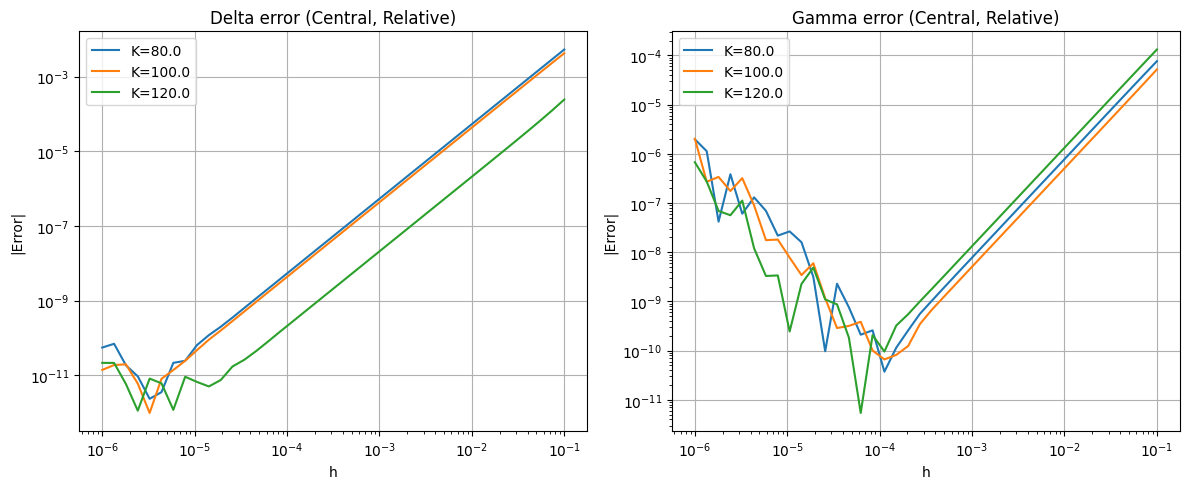

In [3]:
strikes = [80.0, 100.0, 120.0]
h_vals = np.logspace(-6, -1, 40)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for k in strikes:
    c = EuropeanContract(Stock.TEST_COMPANY, PutCallFwd.CALL, LongShort.LONG, k, 1.0)
    p = EuropeanAnalyticPricer(c, FlatVolModel(Stock.TEST_COMPANY), Params())
    ad = p.calc_delta(GreekMethod.ANALYTIC)
    ag = p.calc_gamma(GreekMethod.ANALYTIC)
    
    err_d = []
    err_g = []
    for h in h_vals:
        Pricer.fd_method = FiniteDifferenceMethod.CENTRAL
        Pricer.bump_type = BumpType.RELATIVE
        Pricer.bump_size = h
        err_d.append(abs(p.calc_delta(GreekMethod.BUMP) - ad))
        err_g.append(abs(p.calc_gamma(GreekMethod.BUMP) - ag))
        
    axes[0].loglog(h_vals, err_d, label=f'K={k}')
    axes[1].loglog(h_vals, err_g, label=f'K={k}')

axes[0].set_title('Delta error (Central, Relative)')
axes[0].set_xlabel('h')
axes[0].set_ylabel('|Error|')
axes[0].legend()
axes[0].grid(True)

axes[1].set_title('Gamma error (Central, Relative)')
axes[1].set_xlabel('h')
axes[1].set_ylabel('|Error|')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### 3. Summary
- **Absolute vs Relative:** Relative bumping is preferred as it is scale-independent of the underlying spot price.
- **Optimal bump size:**
  - For Delta: $h \approx 10^{-4}$ (relative)
  - For Gamma: $h \approx 10^{-3}$ (relative)